In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.func import vmap
from torch.func import grad
from torch.func import hessian
from torch.func import jacfwd

from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tqdm
from tqdm import trange

In [ ]:
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda:0


# Lagrangiano con simetrias

$L(\vec{r}_1, \dot{\vec{r}}_1, \vec{r}_2, \dot{\vec{r}}_2, t) = \frac{1}{2} (m_1 {\dot{{r}}}_1^2 + m_2 {\dot{{r}}}_2^2) - \frac{k}{2} (\vec{r}_1 - \vec{r}_2)^2$

En vez de pedirle a la parte que es una caja negra que tenga las simetrias del Lagrangiano (traslacion y rotacion), voy a agregar una parte que aplique transformaciones de simetria para llegar a un "estado canonico", y le paso esas coordenadas transformadas a la red. Asi consigo que toda la funcion tenga las variables necesarias para hacer Euler-Lagrange y ademas que las simetrias no sean aproximaciones de la red.

Si hago el batching con vmap hay limitaciones raras.
https://docs.pytorch.org/docs/stable/func.ux_limitations.html#ux-limitations


No puedo hacer un cambio de sistema de referencia directamente porque no es una simetria del lagrangiano, lo cambia en una derivada total $\frac{dG}{dt}=(m_1\dot{\vec{r}_1}+m_2\dot{\vec{r}_2})\cdot\vec{v}$. Podria agregar una segunda red que modele $G(\vec{r}_1,\vec{r}_2)$, y agregar al lagrangiano un termino $\int\frac{dG}{dt}d\dot{x}$, pero me imagino que la integral va a hacer que sea dificil entrenarla.

 Estaria buena poder meter esta simetria porque saca dos grados de libertad, y si cada input individual de la red puede tener 100 valores diferentes, entonces cada grado de libertad que saco divide por 100 la cantidad de estados en los que la red tiene que funcionar bien

In [ ]:
# Quisiera usar JIT como en el paper, pero el Hessiano
# da 0 siempre cuando lo uso, y no entiendo por que

class SymmetricLagrangianNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(8,600)
    self.fc2 = nn.Linear(600,600)
    self.fc3 = nn.Linear(600,1)
    self.act = nn.Softplus()

    self.fc1.weight.data = nn.init.normal_(self.fc1.weight.data, 0, 2.2/np.sqrt(600))
    self.fc2.weight.data = nn.init.normal_(self.fc2.weight.data, 0, 0.58/np.sqrt(600))
    self.fc3.weight.data = nn.init.normal_(self.fc3.weight.data, 0, 600/np.sqrt(600))

  def forward(self, pos, vel):
    r1,r2 = pos.split(2)
    v1,v2 = vel.split(2)

    # Simetria de traslacion/cons. momento
    # Pongo el origen en r2
    r1 = r1 - r2
    r2 = r2 - r2

    # Simetria de rotacion/cons. m. angular
    # Oriento r1-r2 en la direccion x
    """theta = -1 * torch.arctan(r1[1]/(torch.abs(r1[0]) + 0.001))
    R = torch.tensor(data=[
      [torch.cos(theta), -torch.sin(theta)],
      [torch.sin(theta), torch.cos(theta)]
    ], dtype=torch.float32, device=DEVICE)"""
    """R = pos.new_zeros(size=(2,2))
    R[0][0] = torch.cos(theta)
    R[0][1] = - torch.sin(theta)
    R[1][0] = torch.sin(theta)
    R[1][1] = torch.cos(theta)
    r1 = torch.matmul(R,r1)
    v1 = torch.matmul(R,v1)
    v2 = torch.matmul(R,v2)"""
    # No consigo escribirlo de forma que sea compatible con vmap

    x = torch.cat((r1,r2,v1,v2))
    #x = torch.cat((pos,vel))
    x = self.act(self.fc1(x))
    x = self.act(self.fc2(x))
    x = self.fc3(x)
    return x.squeeze(-1)

In [ ]:
# Un sistema de dos masas que interactuan elasticamente
m1 = 1
m2 = 2
k = 5

def realLagrangian(pos, vel):
  r1 = pos[0:2]
  r2 = pos[2:4]
  r1_t = vel[0:2]
  r2_t = vel[2:4]

  return 1/2 * (m1 * (r1_t**2).sum() + m2 * (r2_t**2).sum()) - k/2 * ((r1-r2)**2).sum()

def realAcceleration(pos, vel):
  r1 = pos[0:2]
  r2 = pos[2:4]

  a1 = k/m1 * (r2 - r1)
  a2 = k/m2 * (r1 - r2)

  return torch.cat((a1,a2))

TODO: probar si puedo achicar la red

https://greydanus.github.io/2020/03/10/lagrangian-nns/

Definiendo

$\bar{\eta} = \begin{pmatrix}x_1\\y_1\\x_2\\y_2\end{pmatrix}$

Euler-Lagrange es

$(\bar\nabla_\dot{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L) \ddot{\bar{\eta}}
= \bar{\nabla}_{\bar{\eta}}L
- (\bar\nabla_{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L) \dot{\bar{\eta}}
$

Defino

$\bar{\bar{M}} = \bar\nabla_\dot{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L$

$\bar{\bar{G}} = \bar\nabla_{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L$

$\bar{F} = \bar{\nabla}_{\bar{\eta}}L$

De forma tengo que resolver la ecuacion

$\bar{\bar{M}}\ddot{\bar{\eta}} = \bar{F} - \bar{\bar{G}} \dot{\bar{\eta}}$

para econtrar $\ddot{\vec{\eta}}$




In [ ]:
def getAcceleration(L, pos, vel):
  M = hessian(L, argnums=1)(pos, vel)
  G = jacfwd(grad(L, argnums=1), argnums=0)(pos, vel)
  F = grad(L, argnums=0)(pos, vel)

  return torch.linalg.solve(M, F - torch.matmul(G, vel))

In [ ]:
# En el github de Cranmer hay dos implementaciones diferentes
# de la red y el entrenamiento.
# En el tutorial entrenan una red de ~100 neuronas con datos
# que forman una trayectoria.
# Pero en el codigo que usaron para el paper entrenan una red
# de 600 neuronas con datos aleatorios
# Voy a seguir el paper

n_epochs = 7
n_batches_per_epoch = 2000
batch_size = 500

def getEpochData():
  # Organizo los inputs segun cuando se usan en el entrenamiento
  train_states = torch.rand(size=(n_batches_per_epoch, batch_size, 8))
  train_states = train_states.to(DEVICE)

  getTarget = lambda state: realAcceleration(state[0:4], state[4:8])

  # TODO buscar una forma mas legible de poner las aceleraciones
  # en esta estructura
  train_targets = vmap(
    # Procesa cada batch
    vmap(
      # cada estado
      getTarget,
      in_dims = 0
    ),
    in_dims = 0
  )(train_states)

  return train_states, train_targets

In [ ]:
# Con esta seed alcanza loss=0.00097 en 6 epochs (7min con T4 en collab)
torch.random.manual_seed(5)

model = SymmetricLagrangianNet()
model = model.to(DEVICE)

prediction = lambda state: getAcceleration(model, state[0:4], state[4:8])

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
# El paper usa varios lr, pero no entiendo como implementarlo

train_history = []
# Como los datos son aleatorios, no hay un dataset fijo
# que pueda overfitear. Creo que no aportaria nada
# tener tests. Lo que si puede pasar es que los minimos de
# loss durante el entrenamiento ocurran porque justo se genero
# un batch para el que el modelo sea mejor.

In [ ]:
starting_epoch = 0 #Por si quiero resumir el entrenamiento

for epoch in trange(starting_epoch, n_epochs):
  train_states, train_targets = getEpochData()

  for i in range(n_batches_per_epoch):
    batch_states = train_states[i]
    batch_targets = train_targets[i]

    output = vmap(prediction, in_dims=0)(batch_states)
    loss = criterion(output, batch_targets)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print(str(np.round(loss.detach().item(),5)))

    train_history.extend([loss.detach().item()])

Text(0.5, 0, 'batch')

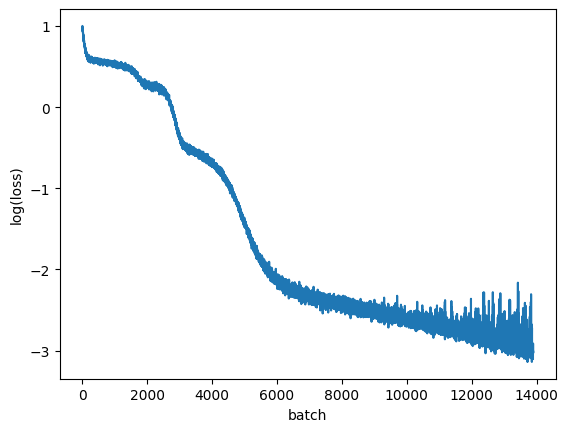

In [ ]:
plt.plot(np.log10(train_history[100:]))
plt.ylabel("log(loss)")
plt.xlabel("batch")

Me imagino que el ancho del grafico indica que hay overfitting: la loss depende cada vez mas de los batches individuales. No parece estar empeorando en los peores casos: el "lim sup" sigue en 10^-2, pero igual no voy a seguir entrenando.

Aunque no haya un dataset fijo, puede que la simetrizacion haga que algunos inputs a la red neuronal sean mas probables, y la red esta haciendo overfitting a esos.

https://mathworld.wolfram.com/UniformDifferenceDistribution.html

Como la distribucion de x1 y x2 es uniforme, la distribucion de x1-x2, que es una variable que le paso a la red para asegurar simetria de traslacion, tiende a tomar valores cerca de 0.

Me imagino que podria corregir un poco esto multiplicando la loss por un termino inversamente proporcional a que tan probable es el conjunto de estados en la que esta evaluada, asi le da menos importancia a ajustar correctamente los estados muy comunes.

Como en una trayectoria real los estados en los que las particulas estan alejadas son mas frecuentes (porque ahi la energia cinetica es mas baja), es importante que el modelo funcione bien en esos

In [ ]:
torch.save(model.state_dict(), "half_sym_m3.pt")

In [ ]:
n_epochs = 10
torch.random.manual_seed(5)

model2 = SymmetricLagrangianNet()
model2 = model2.to(DEVICE)

prediction2 = lambda state: getAcceleration(model2, state[0:4], state[4:8])

criterion = nn.MSELoss()
optimizer2 = optim.Adam(model2.parameters(), lr=0.001)
#

train_history2 = []

In [ ]:
starting_epoch = 0 #Por si quiero resumir el entrenamiento

# Como el batch_size es grande, la probabilidad real de cada batch
# entero es minuscula. Quise usar un multiplo de la probabilidad,
# pero los resultados son o muy chicos o muy grandes.
# Voy a usar la mediana de las probabilidades
probability = lambda state: 2.6*(1 - torch.abs(state[0] - state[2]))*(1 - torch.abs(state[1] - state[3]))
batch_probability = lambda batch: torch.median(vmap(probability, in_dims=0)(batch))

for epoch in trange(starting_epoch, n_epochs):
  train_states, train_targets = getEpochData()

  for i in range(n_batches_per_epoch):
    batch_states = train_states[i]
    batch_targets = train_targets[i]

    output = vmap(prediction2, in_dims=0)(batch_states)
    #print(output)
    #print(probability(batch_states[0]))
    #print(batch_probability(batch_states))
    loss = criterion(output, batch_targets) / batch_probability(batch_states)

    optimizer2.zero_grad()
    loss.backward()
    optimizer2.step()

    real_loss = loss * (batch_probability(batch_states))

    print(str(np.round(real_loss.detach().item(),5)))

    train_history2.extend([real_loss.detach().item()])

Text(0.5, 0, 'batch')

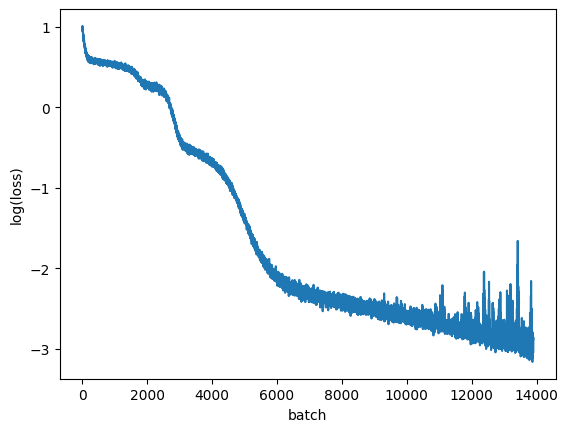

In [ ]:
plt.plot(np.log10(train_history2[100:-6000]))
plt.ylabel("log(loss)")
plt.xlabel("batch")

In [ ]:
torch.save(model2.state_dict(), "half_sym_weighted_m3.pt")

No parece haber ayudado mucho. El grafico es un poco mas angosto, pero ahora tiene picos mucho mas altos. Puede que esos picos sean debido a batches muy poco probables que hacen que el modelo ajuste demasiado.

Antes de hacer comparaciones, entreno una red que no sea lagrangiana para comparar.

In [ ]:
class SymmetricBaselineNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(8,600)
    self.fc2 = nn.Linear(600,600)
    self.fc3 = nn.Linear(600,4)
    self.act = nn.Softplus()

    self.fc1.weight.data = nn.init.normal_(self.fc1.weight.data, 0, 2.2/np.sqrt(600))
    self.fc2.weight.data = nn.init.normal_(self.fc2.weight.data, 0, 0.58/np.sqrt(600))
    self.fc3.weight.data = nn.init.normal_(self.fc3.weight.data, 0, 600/np.sqrt(600))

  def forward(self, pos, vel):
    r1,r2 = pos.split(2)
    v1,v2 = vel.split(2)

    # Simetria de traslacion/cons. momento
    # Pongo el origen en r2
    r1 = r1 - r2
    r2 = r2 - r2

    # Simetria galileana
    # Como no voy a usar Euler-Lagrange, no importa que esta sea
    # una cuasi-simetria del lagrangiano, porque es una simetria
    # exacta de la ecuacion de newton
    v1 = v1 - v2
    v2 = v2 - v2

    x = torch.cat((r1,r2,v1,v2))
    #x = torch.cat((pos,vel))
    x = self.act(self.fc1(x))
    x = self.act(self.fc2(x))
    x = self.fc3(x)
    return x

In [ ]:
n_epochs = 5
torch.random.manual_seed(5)

model3 = SymmetricBaselineNet()
model3 = model3.to(DEVICE)

#predicter3 = lambda state: model3(*state.split(4))
prediction3 = lambda state: model3(state[0:4], state[4:8])

criterion = nn.MSELoss()
optimizer3 = optim.Adam(model3.parameters(), lr=0.001)

train_history3 = []

In [ ]:
starting_epoch = 0

for epoch in trange(starting_epoch, n_epochs):
  train_states, train_targets = getEpochData()

  for i in range(n_batches_per_epoch):
    batch_states = train_states[i]
    batch_targets = train_targets[i]

    output = vmap(prediction3, in_dims=0)(batch_states)
    #print(output[0:5])
    loss = criterion(output, batch_targets)

    optimizer3.zero_grad()
    loss.backward()
    optimizer3.step()

    print(str(np.round(loss.detach().item(),5)))

    train_history3.extend([loss.detach().item()])

In [ ]:
model = SymmetricLagrangianNet()
model2 = SymmetricLagrangianNet()

model.load_state_dict(torch.load("half_sym_m3.pt"))
model2.load_state_dict(torch.load("half_sym_weighted_m3.pt"))

Simulo una trayectoria con las tres redes y la aceleracion analitica

In [ ]:
# Robado de https://colab.research.google.com/drive/1CSy-xfrnTX28p1difoTA8ulYw0zytJkq
def rk4_step(f, h, t, x):
  # one step of runge-kutta integration
  k1 = h * f(x, t)
  k2 = h * f(x + k1/2, t + h/2)
  k3 = h * f(x + k2/2, t + h/2)
  k4 = h * f(x + k3, t + h)
  return x + 1/6 * (k1 + 2 * k2 + 2 * k3 + k4)

In [ ]:
initial_state = torch.tensor(
    [0,0,0,1,0.5,0,0.5,0], device = DEVICE
)

real_trajectory = initial_state.unsqueeze(0)
model_trajectory = initial_state.unsqueeze(0)
model_median_prob_trajectory = initial_state.unsqueeze(0)
model_baseline_trajectory = initial_state.unsqueeze(0)

realChange = lambda state, t: torch.cat((state[4:8], realAcceleration(state[0:4], state[4:8])))
modelChange = lambda L, state, t: torch.cat((state[4:8], getAcceleration(L,state[0:4], state[4:8])))
modelBaselineChange = lambda state, t: torch.cat((state[4:8], prediction3(state)))

t = torch.linspace(0,10,1000)
dt = 10/1000

for i in tqdm.tqdm(t):
  real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
  model_trajectory = torch.cat((model_trajectory, (rk4_step(partial(modelChange, model), dt, 0, model_trajectory[-1])).unsqueeze(0)))
  model_median_prob_trajectory = torch.cat((model_median_prob_trajectory, (rk4_step(partial(modelChange, model2), dt, 0, model_median_prob_trajectory[-1])).unsqueeze(0)))
  model_baseline_trajectory = torch.cat((model_baseline_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_trajectory[-1]).unsqueeze(0))))

100%|██████████| 1000/1000 [01:58<00:00,  8.40it/s]


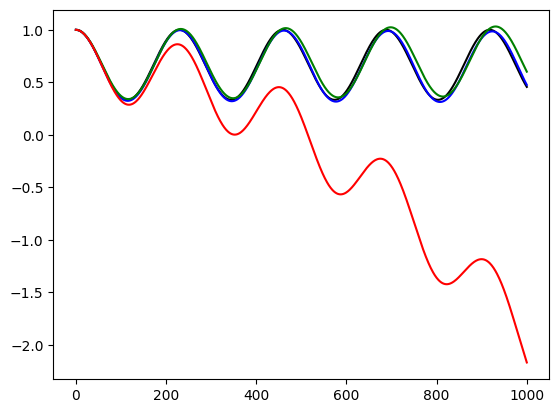

In [ ]:
plt.plot(real_trajectory[:,3].cpu(), color="black")
plt.plot(model_median_prob_trajectory[:,3].cpu().detach(), color="blue")
plt.plot(model_trajectory[:,3].cpu().detach(), color="green")
plt.plot(model_baseline_trajectory[:,3].cpu().detach(), color="red")

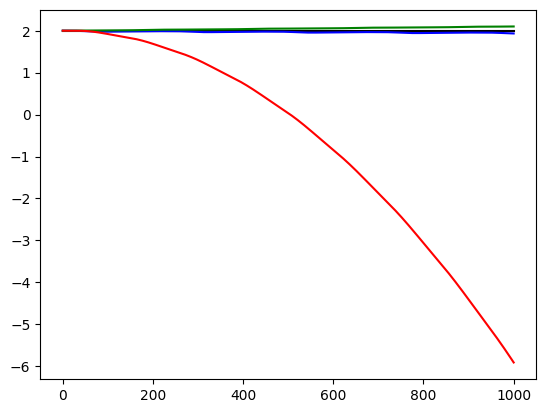

In [ ]:
# Centro de masa

plt.plot(m1 * real_trajectory[:,1].cpu() + m2 * real_trajectory[:,3].cpu(), color="black")
plt.plot(m1 * model_median_prob_trajectory[:,1].cpu().detach() + m2 * model_median_prob_trajectory[:,3].cpu().detach(), color="blue")
plt.plot(m1 * model_trajectory[:,1].cpu().detach() + m2 * model_trajectory[:,3].cpu().detach(), color="green")
plt.plot(m1 * model_baseline_trajectory[:,1].cpu().detach() + m2 * model_baseline_trajectory[:,3].cpu().detach(), color="red")

Las lagrangianas son mucho mejores. Voy a comparalas entre si

In [ ]:
model.eval()
model2.eval()

def get_distance(real_state, model_state):
  real_pos, real_vel = real_state.split(4)
  model_pos, model_vel = model_state.split(4)

  # No es realmente la distancia entre dos puntos,
  # pero sirve igual para ver que tan parecidos
  # son los estados
  return ((real_pos - model_pos)**2).sum().cpu().detach()

initials = []
model_errors = []
model_weighted_errors = []

for _ in trange(10):
  initial_state = torch.rand(size=(8,), device=DEVICE)
  initials.extend([initial_state])
  real_trajectory = initial_state.unsqueeze(0)
  model_trajectory = initial_state.unsqueeze(0)
  model_median_prob_trajectory = initial_state.unsqueeze(0)

  model_error = []
  model_median_prob_error = []

  t = torch.linspace(0,2,200)
  dt = 10/1000

  for i in t:
    real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
    model_trajectory = torch.cat((model_trajectory, (rk4_step(partial(modelChange, model), dt, 0, model_trajectory[-1]).unsqueeze(0))))
    model_median_prob_trajectory = torch.cat((model_median_prob_trajectory, (rk4_step(partial(modelChange, model2), dt, 0, model_median_prob_trajectory[-1]).unsqueeze(0))))

    model_error.extend([get_distance(real_trajectory[-1], model_trajectory[-1])])
    model_median_prob_error.extend([get_distance(real_trajectory[-1], model_median_prob_trajectory[-1])])

  model_errors.extend([model_error])
  model_weighted_errors.extend([model_median_prob_error])

100%|██████████| 10/10 [03:49<00:00, 22.93s/it]


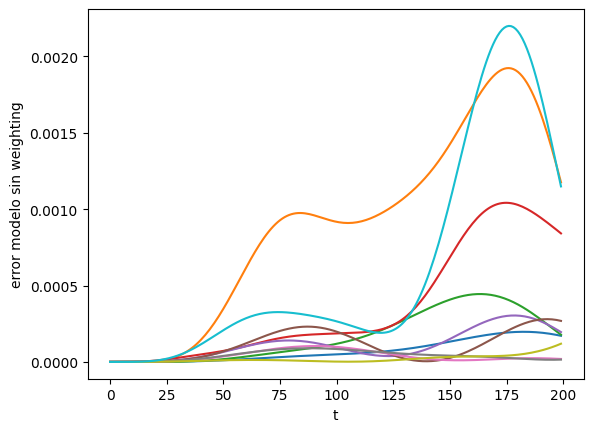

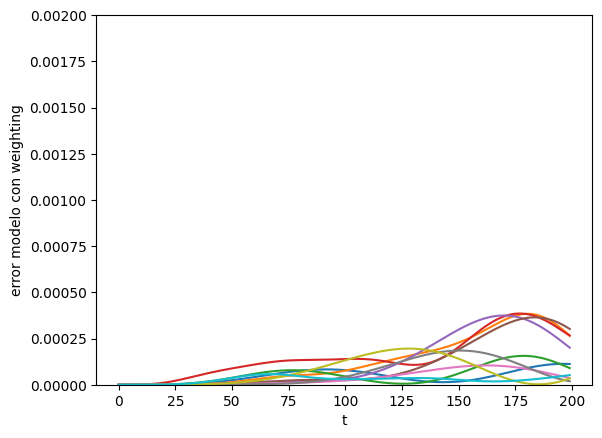

In [ ]:
plt.ylabel("error modelo sin weighting")
plt.xlabel("t")
for i in model_errors:
  plt.plot(i)
plt.show()

plt.ylabel("error modelo con weighting")
plt.ylim([0,0.002])
plt.xlabel("t")
for i in model_weighted_errors:
  plt.plot(i)
plt.show()

O sea que corregir el overfitting mejora las predicciones

# Mejora de conservacion de energia usando simetria temporal

Si para un sistema tengo una trayectoria $\vec{r}(t)$, hay dos formas de llegar a la trayectoria "en reversa" $\vec{s}(t) = \vec{r}(-t)$

La primera es matematica. Si tengo la velocidad y la aceleracion, entonces

$$\vec{s}(t+dt) = \vec{s}(t) + \dot{\vec{s}}(t)dt = \vec{r}(-t) - \dot{\vec{r}}(-t)dt$$
$$\dot{\vec{s}}(t+dt) = \dot{\vec{s}}(t) +\ddot{\vec{s}}(t)dt = -\dot{\vec{r}}(-t) + \ddot{\vec{r}}(-t)dt$$

La segunda es fisica. Si las ecuaciones de movimiento son reversibles, para toda trayectoria con condiciones iniciales $\vec{r}_0, \dot{\vec{r}}_0$ hay otra trayectoria, con condiciones iniciales $\vec{r}_0, -\dot{\vec{r}}_0$ que es identica pero en reversa.

Si la red baseline hace que **todas** las trayectorias pierdan energia, entonces ya no son equivalentes las dos versiones en reversa de una trayectoria: la matematica gana energia, y la fisica pierde energia (porque es una trayectoria mas). Se me ocurre que podria alternar entre ambas para intentar que se conserve mejor la energia.

Lo que voy a hacer es usar la baseline que ya entrene, y alternar entre usarla normalmente y usar la reversa matematica de la trayectoria con condiciones iniciales opuestas. No voy a entrenarla, solo usarla.

pero primero tengo que ver que **todas** las trayectorias pierdan energia

100%|██████████| 10/10 [01:15<00:00,  7.51s/it]


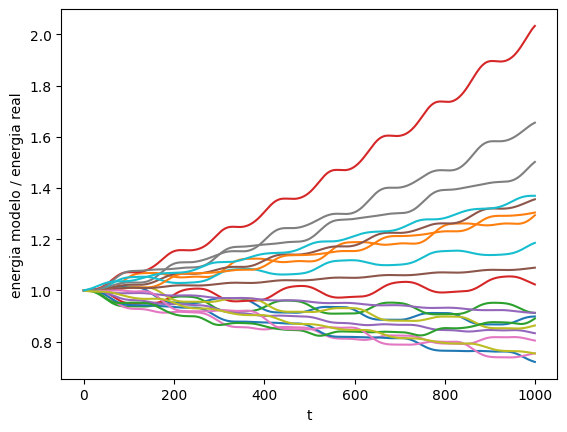

In [ ]:
energies = []
initials = []

def get_energy(state):
  pos, vel = state.split(4)
  return m1/2 * (vel[0]**2 + vel[1]**2) + m2/2 * (vel[2]**2 + vel[3]**2) + k/2 * ((pos[2] - pos[0])**2 + (pos[3] - pos[1])**2)

for _ in trange(10):
  energy = []

  initial_state = torch.rand(size=(8,), device=DEVICE)
  initials.extend([initial_state])
  real_trajectory = initial_state.unsqueeze(0)
  model_baseline_flipping_trajectory = initial_state.unsqueeze(0)

  t = torch.linspace(0,10,1000)
  dt = 10/1000

  for i in t:
    real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
    model_baseline_flipping_trajectory = torch.cat((model_baseline_flipping_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_flipping_trajectory[-1]).unsqueeze(0))))

    real_energy = get_energy(real_trajectory[-1])
    model_energy = get_energy(model_baseline_flipping_trajectory[-1])
    energy.extend([(model_energy / real_energy).cpu().item()])

  plt.plot(energy)
  energies.extend([energy])

  energy = []
  initial_pos, initial_vel = initial_state.split(4)
  initial_state = torch.cat((initial_pos, -initial_vel))
  initials.extend([initial_state])
  real_trajectory = initial_state.unsqueeze(0)
  model_baseline_flipping_trajectory = initial_state.unsqueeze(0)

  for i in t:
    real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
    model_baseline_flipping_trajectory = torch.cat((model_baseline_flipping_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_flipping_trajectory[-1]).unsqueeze(0))))

    real_energy = get_energy(real_trajectory[-1])
    model_energy = get_energy(model_baseline_flipping_trajectory[-1])
    energy.extend([(model_energy / real_energy).cpu().item()])


  plt.plot(energy)
  energies.extend([energy])
plt.ylabel("energia modelo / energia real")
plt.xlabel("t")
plt.show()


Asi que al final no todas pierden energia. Al menos en este caso de las dos particulas con interaccion elastica

In [ ]:
# Cual es esa que crece rapido?
for i in energies:
  print(i[-1])

0.8980379104614258
1.2934541702270508
0.911609411239624
1.0232009887695312
0.8327213525772095
1.3557628393173218
0.8040304183959961
1.6549584865570068
0.8629630208015442
1.1856119632720947
0.7205958962440491
1.3041296005249023
0.8900431990623474
2.0328726768493652
0.9126099348068237
1.0887030363082886
0.7539471983909607
1.501656174659729
0.7536704540252686
1.3693866729736328


In [ ]:
initial_state = torch.tensor(data=[ 0.0491,  0.3736,  0.6786,  0.1596, -0.2163, -0.9965, -0.5093, -0.8976], device=DEVICE)

t = torch.linspace(0,500,50000)
dt = 10/10000

real_trajectory = initial_state.unsqueeze(0)
model_baseline_trajectory = initial_state.unsqueeze(0)
real_energy = [get_energy(initial_state)]
model_energy = [get_energy(initial_state)]

for i in tqdm.tqdm(t):
  real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
  model_baseline_trajectory = torch.cat((model_baseline_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_trajectory[-1]).unsqueeze(0))))

  real_energy.extend([get_energy(real_trajectory[-1]).cpu().item()])
  model_energy.extend([get_energy(model_baseline_trajectory[-1]).cpu().item()])

100%|██████████| 50000/50000 [02:59<00:00, 277.82it/s]


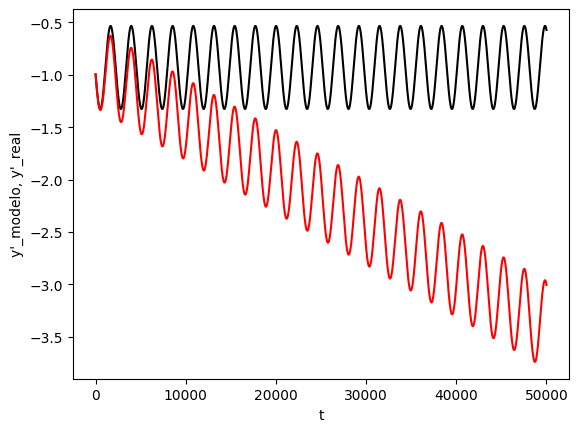

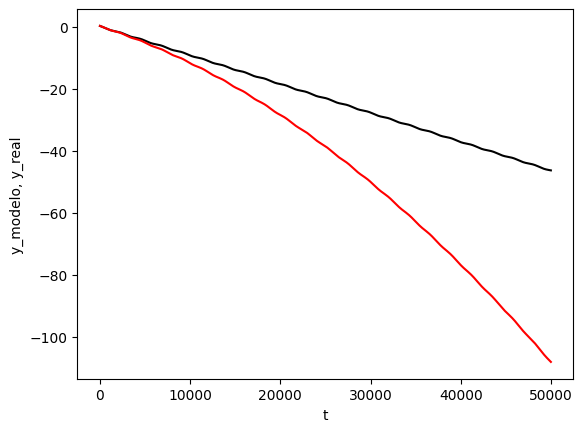

In [ ]:
plt.ylabel("y'_modelo, y'_real")
plt.xlabel("t")
plt.plot(real_trajectory[:,5].cpu(), color="black")
plt.plot(model_baseline_trajectory[:,5].cpu().detach(), color="red")
plt.show()

plt.ylabel("y_modelo, y_real")
plt.xlabel("t")
plt.plot(real_trajectory[:,1].cpu(), color="black")
plt.plot(model_baseline_trajectory[:,1].cpu().detach(), color="red")
plt.show()

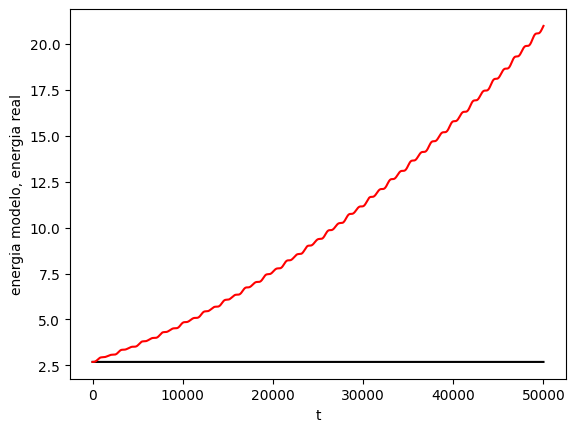

In [ ]:
#real_energy[0] = real_energy[0].cpu()
#model_energy[0] = model_energy[0].cpu()

plt.ylabel("energia modelo, energia real")
plt.xlabel("t")
plt.plot(real_energy, color="black")
plt.plot(model_energy, color="red")